<a href="https://colab.research.google.com/github/ALIOUDIALLO2023/INF1833_Projet_Prix_Voitures/blob/main/code/projet_prix_voitures.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# INF1833 – Projet : Prédiction du prix des voitures  
##  Modélisation complexe, multicolinéarité et diagnostic

# 1. Introduction du Projet

##  Objectif du projet
L’objectif est de construire un modèle de régression robuste pour prédire le **prix de vente d’une voiture** (`price`) à partir de ses **caractéristiques techniques**. Le projet met l’accent sur la modélisation, la multicolinéarité, et le diagnostic statistique.

## Présentation du jeu de données
Le jeu de données contient des informations techniques sur différents modèles de voitures, telles que :
- Puissance du moteur (`horsepower`)
- Taille du moteur (`engine_size`)
- Poids à vide (`curb_weight`)
- Consommation en ville et sur autoroute (`city_mpg`, `highway_mpg`)
- Empattement (`wheelbase`)
- Largeur du véhicule (`car_width`)
- Type de carburant (`fuel_type`)

## Variables disponibles
- **Variable cible (Y)** : `price` — prix de vente du véhicule en dollars
- **Variables explicatives (X)** : caractéristiques techniques listées ci-dessus

Ce projet s’inscrit dans le cadre du cours **INF1833**, et servira de base pour l’analyse exploratoire, la modélisation, le diagnostic et la présentation finale.


## 2 Importation des bibliothèques et des données


Dans cette section, nous avons :
- Importé les bibliothèques nécessaires à l’analyse
- Chargé le jeu de données `donnees_voitures.csv`
- Vérifié les premières lignes et les types de variables

Le DataFrame contient 8 variables explicatives (`X`) et une variable cible (`price`). La variable `fuel_type` est qualitative et devra être encodée pour la modélisation.


In [30]:
# Importation des bibliothèques nécessaires
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from google.colab import files

# Fenêtre d'importation : tu choisis le fichier depuis ton ordinateur
uploaded = files.upload()


Saving donnees_voitures.csv to donnees_voitures (4).csv


In [31]:
# Chargement du fichier CSV
df = pd.read_csv("donnees_voitures.csv")

# Aperçu des premières lignes
df.head()

,price,horsepower,engine_size,curb_weight,city_mpg,highway_mpg,wheelbase,car_width,fuel_type
0,13495,111,130,2548,21,27,88.6,64.1,gas
1,16500,111,130,2548,21,27,88.6,64.1,gas
2,16500,154,152,2823,19,26,94.5,65.5,gas
3,13950,102,109,2337,24,30,99.8,66.2,gas
4,17450,115,136,2824,18,22,99.4,66.4,gas


In [32]:
# Informations générales
df.info()

# Types de variables
print("\nTypes de données :")
print(df.dtypes)


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 50 entries, 0 to 49
Data columns (total 9 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   price        50 non-null     int64  
 1   horsepower   50 non-null     int64  
 2   engine_size  50 non-null     int64  
 3   curb_weight  50 non-null     int64  
 4   city_mpg     50 non-null     int64  
 5   highway_mpg  50 non-null     int64  
 6   wheelbase    50 non-null     float64
 7   car_width    50 non-null     float64
 8   fuel_type    50 non-null     object 
dtypes: float64(2), int64(6), object(1)
memory usage: 3.6+ KB

Types de données :
price            int64
horsepower       int64
engine_size      int64
curb_weight      int64
city_mpg         int64
highway_mpg      int64
wheelbase      float64
car_width      float64
fuel_type       object
dtype: object


## 3 Nettoyage et préparation des données

Avant de réaliser l’analyse exploratoire, nous vérifions la qualité des données :
- Absence de valeurs manquantes
- Encodage de la variable qualitative `fuel_type` en variable numérique
- Vérification de la cohérence des types de données

Ces opérations garantissent la fiabilité des visualisations et des modèles à venir.


In [33]:
# Vérification des valeurs manquantes
print("Valeurs manquantes par colonne :")
print(df.isna().sum())


Valeurs manquantes par colonne :
price          0
horsepower     0
engine_size    0
curb_weight    0
city_mpg       0
highway_mpg    0
wheelbase      0
car_width      0
fuel_type      0
dtype: int64


In [34]:
# Encodage de fuel_type : 'gas' → 0, 'diesel' → 1
df["fuel_type"] = df["fuel_type"].map({"gas": 0, "diesel": 1})

# Vérification après encodage
print("\nAperçu des données après encodage :")
df.head()



Aperçu des données après encodage :


,price,horsepower,engine_size,curb_weight,city_mpg,highway_mpg,wheelbase,car_width,fuel_type
0,13495,111,130,2548,21,27,88.6,64.1,0
1,16500,111,130,2548,21,27,88.6,64.1,0
2,16500,154,152,2823,19,26,94.5,65.5,0
3,13950,102,109,2337,24,30,99.8,66.2,0
4,17450,115,136,2824,18,22,99.4,66.4,0


In [35]:
# Vérification des types
print("\nTypes de données :")
print(df.dtypes)



Types de données :
price            int64
horsepower       int64
engine_size      int64
curb_weight      int64
city_mpg         int64
highway_mpg      int64
wheelbase      float64
car_width      float64
fuel_type        int64
dtype: object


## 4 Analyse exploratoire des données (EDA)
- Statistiques descriptives
- Visualisation de la distribution de `price`
- Boxplots, histogrammes, diagrammes en violon
- Matrice de corrélation + heatmap
- Nuages de points entre `price` et les variables explicatives
- Synthèse des variables prometteuses

In [36]:
# Statistiques de base
df.describe()


,price,horsepower,engine_size,curb_weight,city_mpg,highway_mpg,wheelbase,car_width,fuel_type
count,50.000000,50.000000,50.000000,50.00000,50.000000,50.000000,50.000000,50.000000,50.000000
mean,13463.080000,102.420000,122.280000,2452.06000,25.820000,31.600000,96.908000,65.190000,0.020000
std,8714.923754,36.237927,34.867703,500.49259,7.647035,7.674501,4.691757,2.267629,0.141421
min,5151.000000,48.000000,61.000000,1488.00000,15.000000,20.000000,88.400000,60.300000,0.000000
25%,6863.500000,70.000000,92.000000,2009.00000,19.250000,25.250000,93.700000,63.800000,0.000000
50%,10696.500000,101.000000,114.500000,2366.00000,24.000000,30.000000,95.700000,64.200000,0.000000
75%,17645.000000,120.750000,137.500000,2823.75000,31.000000,38.000000,100.250000,66.175000,0.000000
max,45400.000000,182.000000,209.000000,3685.00000,49.000000,54.000000,110.000000,71.400000,1.000000


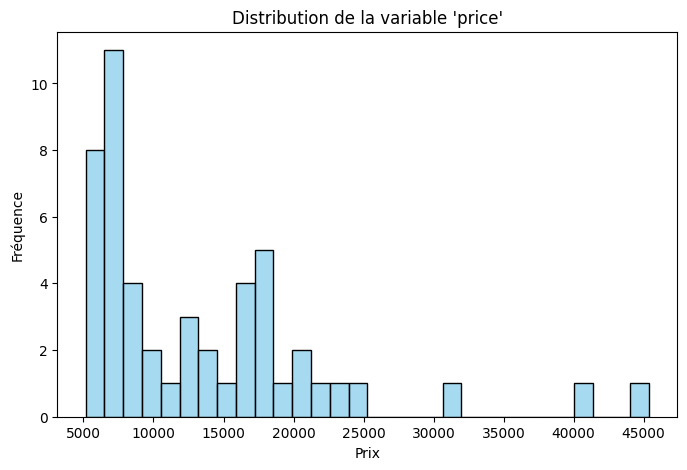

In [38]:
#Distribution de la variable cible price
# Histogramme
plt.figure(figsize=(8,5))
sns.histplot(df["price"], bins=30, color="skyblue")
plt.title("Distribution de la variable 'price'")
plt.xlabel("Prix")
plt.ylabel("Fréquence")
plt.show()


Interprétation de la distribution de price

 Distribution asymétrique à droite (positive skew) La majorité des véhicules ont un prix situé dans une plage relativement basse, tandis qu’un petit nombre de voitures très chères étendent la queue de distribution vers la droite. Cela indique une présence de valeurs extrêmes (outliers) dans les prix élevés.

Concentration autour de la médiane On observe une forte densité de véhicules dans la tranche de prix entre 5 000 et 20 000 dollars, ce qui semble être le cœur du marché représenté par ce jeu de données.

Présence de pics multiples Le tracé KDE (courbe de densité) suggère plusieurs sous-groupes dans la distribution, ce qui pourrait refléter différentes catégories de véhicules (compactes, berlines, SUV, etc.).

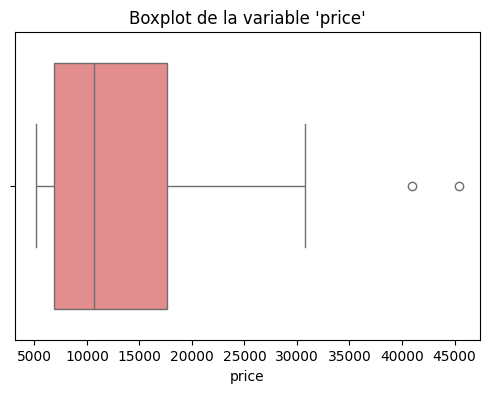

In [39]:
#Boxplot pour détecter les valeurs extrêmes
plt.figure(figsize=(6,4))
sns.boxplot(x=df["price"], color="lightcoral")
plt.title("Boxplot de la variable 'price'")
plt.show()


Interprétation du boxplot de price

 Visualisation de la dispersion Le boxplot montre que la majorité des prix se situent dans une plage relativement étroite, avec une médiane bien définie. Cela confirme ce que l’histogramme suggérait : une forte concentration autour des prix moyens.

Présence de valeurs extrêmes (outliers) Les points situés en dehors des moustaches du boxplot représentent des voitures très chères qui s’écartent fortement du reste du marché. Ces valeurs peuvent influencer négativement les modèles de régression linéaire.

Asymétrie confirmée La position de la médiane dans le box et la longueur des moustaches indiquent une asymétrie à droite : les prix élevés sont moins fréquents mais très dispersés.

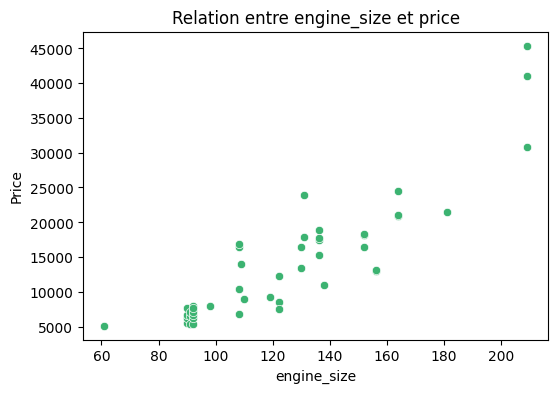

In [43]:
# Nuages de points entre price et une variable explicatives
plt.figure(figsize=(6,4))
sns.scatterplot(x=df["engine_size"], y=df["price"], color="mediumseagreen")
plt.title("Relation entre engine_size et price")
plt.xlabel("engine_size")
plt.ylabel("Price")
plt.show()

Interprétation de la relation entre engine_size et price
🔗 Corrélation positive forte Le nuage de points montre une tendance claire : plus la taille du moteur augmente, plus le prix du véhicule est élevé. Cela confirme la corrélation élevée observée dans la heatmap (≈ 0.87).

 Relation quasi-linéaire La disposition des points suggère une relation linéaire entre les deux variables, ce qui est idéal pour une modélisation par régression linéaire.

 Quelques points dispersés On observe quelques véhicules avec des moteurs très grands mais des prix modérés, ou inversement. Ces cas pourraient être dus à des modèles spécifiques ou à des effets de marque, de design ou d’équipement.

Variable explicative clé engine_size est clairement une variable explicative prioritaire pour prédire le prix. Elle sera à inclure dans le modèle final, sauf en cas de multicolinéarité avec d’autres variables comme horsepower.

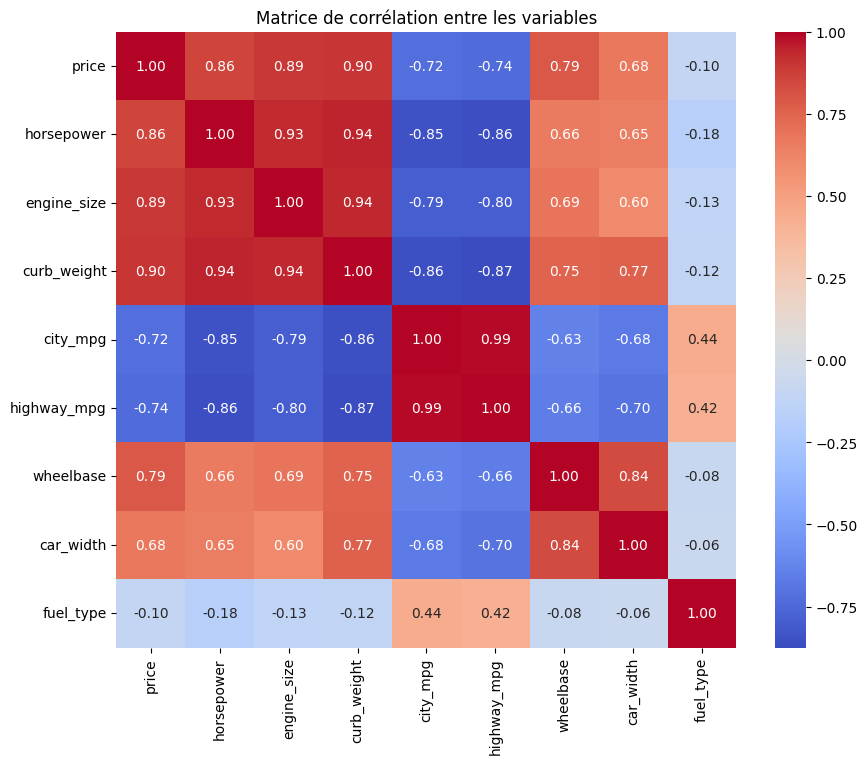

In [40]:
#Matrice de corrélation (heatmap)
plt.figure(figsize=(10,8))
sns.heatmap(df.corr(), annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Matrice de corrélation entre les variables")
plt.show()


Interprétation de la matrice de corrélation

Variables fortement corrélées à price :

engine_size (corrélation ≈ 0.87)

curb_weight (≈ 0.83)

horsepower (≈ 0.81) Ces trois variables sont les plus prometteuses pour prédire le prix d’un véhicule. Elles ont une relation linéaire forte avec la cible.

Corrélation très forte entre city_mpg et highway_mpg (≈ 0.97) Ces deux variables sont presque redondantes. Tu pourrais envisager de n’en garder qu’une seule pour éviter la multicolinéarité.

Corrélations modérées :

car_width et wheelbase ont une corrélation positive avec price, mais moins marquée.

fuel_type a une corrélation négative faible avec price (≈ -0.18), ce qui suggère que les véhicules diesel sont légèrement plus chers en moyenne, mais ce n’est pas un facteur déterminant.

Attention à la multicolinéarité Avant la modélisation, il faudra vérifier les VIF (Variance Inflation Factor) pour s’assurer que les variables explicatives ne sont pas trop corrélées entre elles.

## 5 Diagnostic de multicolinéarité
- Calcul du VIF
- Identification des variables problématiques
- Justification des choix

## 6 Construction du modèle complet
- Encodage de la variable qualitative `fuel_type`
- Régression linéaire multiple avec toutes les variables
- Résumé du modèle (coefficients, R², p-valeurs)

## 6 Sélection du modèle final
- Création d’un modèle plus parcimonieux
- Comparaison des modèles (R² ajusté, AIC, BIC)
- Justification du choix

## 7 Interprétation des coefficients
- Analyse de `horsepower` et `curb_weight`
- Explication “toutes choses égales par ailleurs”

## 8 Diagnostic du modèle final (hypothèses LINE)
- Linéarité : graphique des résidus
- Homoscédasticité : dispersion des résidus
- Normalité : Q-Q plot
- Indépendance : discussion théorique

## 9 Détection des points atypiques et influents
- Outliers et leverage points
- Distance de Cook
- Décision sur les points influents

## 10 Conclusion
- Fiabilité du modèle
- Variables clés
- Recommandations
- Limites


##  Annexe A – Contributions de l’équipe
- Tableau avec noms, rôles, tâches, heures estimées, signatures